In [2]:
import joblib

# Load final tuned model
xgb_best = joblib.load("../model_dir/xgb_best_model.pkl")



# Load test data


X_test_processed = joblib.load("../model_dir/artifacts_dir/X_test_processed.pkl")
y_test = joblib.load("../model_dir/artifacts_dir/y_test.pkl")

print("Model and test data loaded successfully")

print("X_test shape:", X_test_processed.shape)
print("y_test shape:", y_test.shape)

Model and test data loaded successfully
X_test shape: (486, 830)
y_test shape: (486,)


In [3]:
# Generate Probabiliies
yprob_test_xgb = xgb_best.predict_proba(X_test_processed)[:, 1]

# apply final thrshold
final_threshold = 0.35

y_pred_final = (yprob_test_xgb >= final_threshold).astype(int)



from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

print("===== FINAL XGBOOST MODEL EVALUATION =====")

print("Threshold:", final_threshold)

print("Accuracy :", round(accuracy_score(y_test, y_pred_final), 3))
print("Precision:", round(precision_score(y_test, y_pred_final), 3))
print("Recall   :", round(recall_score(y_test, y_pred_final), 3))
print("F1 Score :", round(f1_score(y_test, y_pred_final), 3))
print("ROC-AUC  :", round(roc_auc_score(y_test, yprob_test_xgb), 3))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_final))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_final))

===== FINAL XGBOOST MODEL EVALUATION =====
Threshold: 0.35
Accuracy : 0.813
Precision: 0.271
Recall   : 0.69
F1 Score : 0.389
ROC-AUC  : 0.802

Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.82      0.89       444
           1       0.27      0.69      0.39        42

    accuracy                           0.81       486
   macro avg       0.62      0.76      0.64       486
weighted avg       0.91      0.81      0.85       486

Confusion Matrix:
[[366  78]
 [ 13  29]]


In [4]:
'''
Step 10 — Feature Importance / SHAP

Because we have 830 processed features, first do XGBoost Feature Importance. After that, we'll do SHAP.

'''

"\nStep 10 — Feature Importance / SHAP\n\nBecause we have 830 processed features, first do XGBoost Feature Importance. After that, we'll do SHAP.\n\n"

In [5]:
'''
Step 10A — Get the processed feature names

The important issue is that after preprocessing, names changed because of one-hot encoding. So we need the saved preprocessor.

'''

'\nStep 10A — Get the processed feature names\n\nThe important issue is that after preprocessing, names changed because of one-hot encoding. So we need the saved preprocessor.\n\n'

In [6]:
#Step 10A — Load preprocessor and get feature names
import joblib

preprocessor = joblib.load("../model_dir/preprocessor.pkl")

feature_names = preprocessor.get_feature_names_out()

print("Number of feature names:", len(feature_names))
print("Model input features:", X_test_processed.shape[1])

Number of feature names: 830
Model input features: 830


In [7]:
# Step 10B — Top 20 XGBoost Feature Importances
import pandas as pd
import matplotlib.pyplot as plt

# Get feature importance values from XGBoost
importance_values = xgb_best.feature_importances_

# Create dataframe
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance_values
})

# Sort from highest to lowest
importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

# Select top 20
top_20 = importance_df.head(20)

print(top_20)

                        Feature  Importance
230               num__HCO3_min    0.019287
342                num__BUN_max    0.013779
16                num__sao2_std    0.013551
14                num__sao2_min    0.011616
84                num__BUN_mean    0.011483
301            num__lactate_min    0.010824
36    num__systemicsystolic_std    0.009576
33   num__systemicsystolic_mean    0.009005
228               num__FiO2_min    0.008955
101              num__HCO3_mean    0.008874
25                num__cvp_mean    0.008654
305                 num__pH_min    0.008485
176                num__pH_mean    0.008315
172           num__lactate_mean    0.008294
430            num__lactate_max    0.008242
321      num__total protein_min    0.007522
409            num__albumin_max    0.007328
63                 num__st2_max    0.007102
446   num__serum osmolality_max    0.007072
28                 num__cvp_std    0.006955


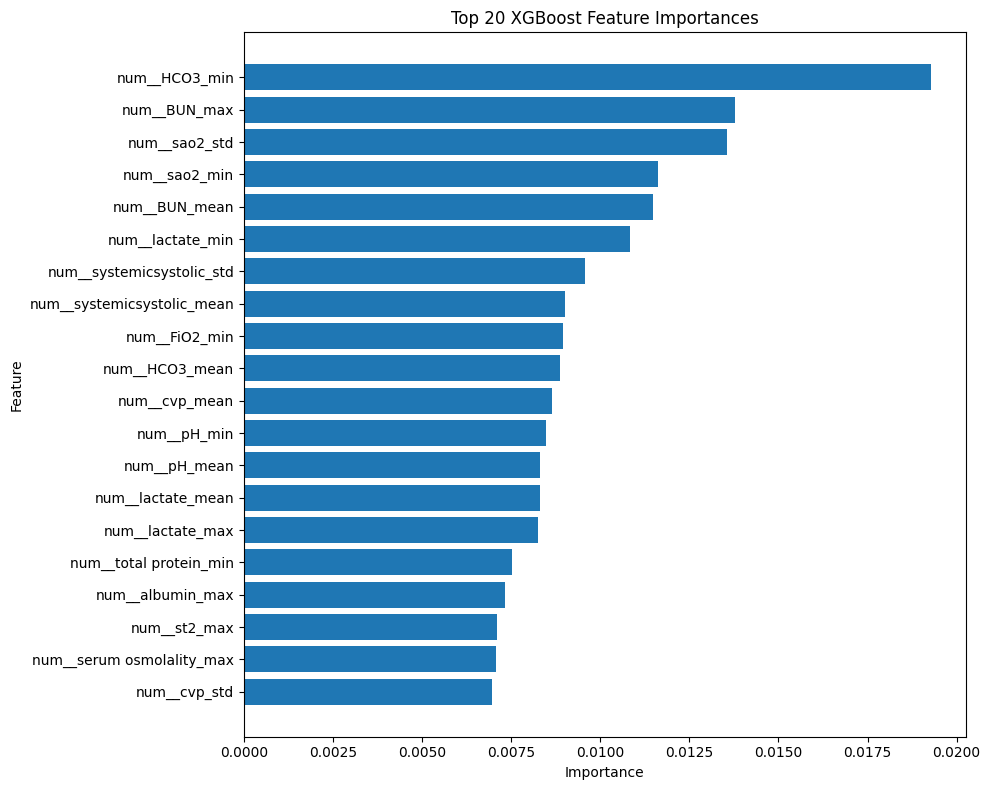

In [8]:
plt.figure(figsize=(10, 8))

plt.barh(
    top_20["Feature"][::-1],
    top_20["Importance"][::-1]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Top 20 XGBoost Feature Importances")

plt.tight_layout()
plt.show()

In [9]:
'''
Note : 

->  A higher importance value means the feature was used more strongly by XGBoost while making splits/predictions.

But this still does not tell us whether that feature pushes mortality risk up or down.  That is why the next step is SHAP.

'''

'\nNote : \n\n->  A higher importance value means the feature was used more strongly by XGBoost while making splits/predictions.\n\nBut this still does not tell us whether that feature pushes mortality risk up or down.  That is why the next step is SHAP.\n\n'

SHAP 

In [10]:
%pip install shap
print ("_"*100)
print ("Installation complted")
print ("_"*100)

Note: you may need to restart the kernel to use updated packages.
____________________________________________________________________________________________________
Installation complted
____________________________________________________________________________________________________



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [11]:

import shap

# Create SHAP explainer for final XGBoost model
explainer = shap.TreeExplainer(xgb_best)

# Calculate SHAP values for test data
shap_values = explainer.shap_values(X_test_processed)
print("length",len(shap_values))
print("SHAP calculation completed")
print("SHAP shape:", shap_values.shape)

c:\2)Projects\ICU_Patient_Predict_Risk_Analysis\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


length 486
SHAP calculation completed
SHAP shape: (486, 830)


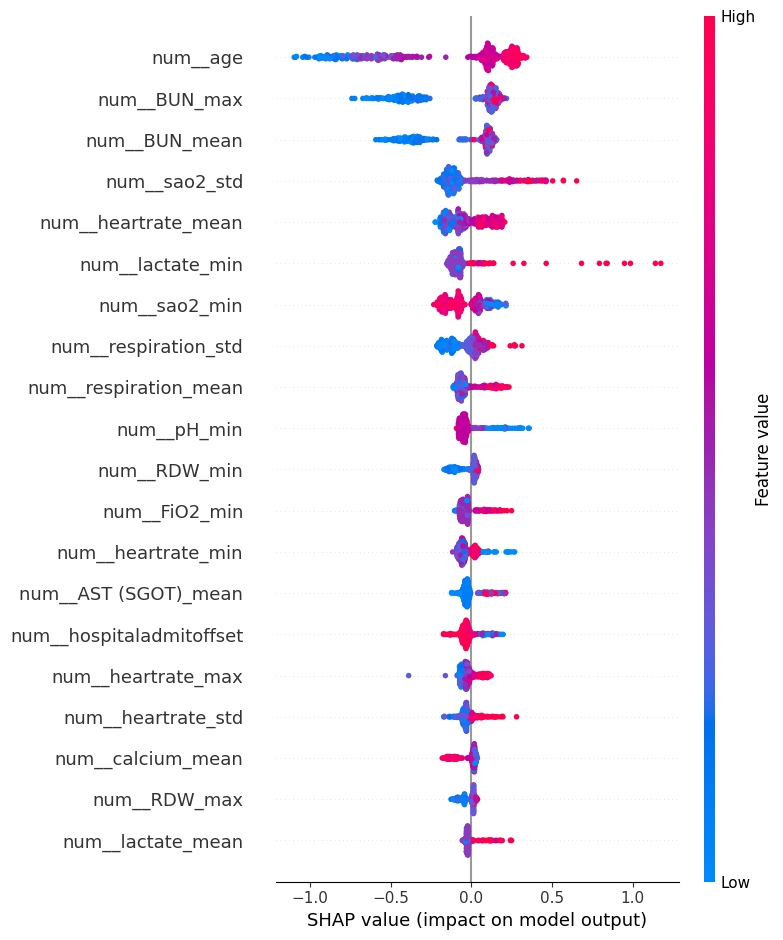

In [12]:
# Step 10D — SHAP Summary Plot.
'''
How to read the graph
Y-axis → Top 20 important features.
X-axis (SHAP value) → effect on model prediction.
Right side (+) → pushes prediction toward Expired (Class 1).
Left side (-) → pushes prediction toward Alive (Class 0).
Red → high feature value; Blue → low feature value.

This is more informative than normal feature importance because it shows both importance and direction of influence.


SHAP > 0  → pushes prediction toward Expired (1)
SHAP < 0  → pushes prediction toward Alive (0)

Red  = high feature value
Blue = low feature value

'''


shap.summary_plot(
    shap_values,
    X_test_processed,
    feature_names=feature_names,
    max_display=20
)

In [13]:
'''
NOTE:


Markdown note for your notebook

SHAP Analysis: SHAP was used to explain the final XGBoost model. Age, BUN, oxygen saturation, heart rate, lactate, respiration, and pH-related features were among the strongest contributors to model predictions. Positive SHAP values push predictions toward mortality (Expired), while negative SHAP values push predictions toward survival (Alive). SHAP provides model-level associations and should not be interpreted as proving clinical causation.



but if you take the feature it has both sides red and blue color , which one has to consider in the diagram

Exactly — you should NOT choose only red or only blue for the whole feature. This is the key idea of a SHAP beeswarm plot.

Take Age from your plot. Each dot represents a different patient:

                AGE
     ALIVE ←      0      → EXPIRED
              SHAP value

Low age 🔵 🔵 🔵  |  🔴 🔴 High age
   -1.0  -0.5     0     +0.2 +0.4

You read color and position together:

🔴 Red on right → high feature value pushes toward Expired
🔴 Red on left → high feature value pushes toward Alive
🔵 Blue on right → low feature value pushes toward Expired
🔵 Blue on left → low feature value pushes toward Alive

So for Age in your actual plot, most low-age blue dots are on the left, while high-age red dots are more toward the right. Therefore the model generally 
learned:

Higher age → pushes toward Expired; lower age → pushes toward Alive.

But you may still see some red and blue dots on both sides. That's normal because SHAP is calculated patient-by-patient, and the effect of one feature can depend on the patient's other features.

Most important rule to remember

Color tells you the feature value. Position tells you the prediction direction.

COLOR                         POSITION

🔴 = high value              LEFT  (<0) = toward Alive
🔵 = low value               RIGHT (>0) = toward Expired

So don't look at red/blue alone. Always ask:

“Where are the red dots located, and where are the blue dots located?”

That's the correct way to interpret your SHAP diagram.

'''

"\nNOTE:\n\n\nMarkdown note for your notebook\n\nSHAP Analysis: SHAP was used to explain the final XGBoost model. Age, BUN, oxygen saturation, heart rate, lactate, respiration, and pH-related features were among the strongest contributors to model predictions. Positive SHAP values push predictions toward mortality (Expired), while negative SHAP values push predictions toward survival (Alive). SHAP provides model-level associations and should not be interpreted as proving clinical causation.\n\n\n\nbut if you take the feature it has both sides red and blue color , which one has to consider in the diagram\n\nExactly — you should NOT choose only red or only blue for the whole feature. This is the key idea of a SHAP beeswarm plot.\n\nTake Age from your plot. Each dot represents a different patient:\n\n                AGE\n     ALIVE ←      0      → EXPIRED\n              SHAP value\n\nLow age 🔵 🔵 🔵  |  🔴 🔴 High age\n   -1.0  -0.5     0     +0.2 +0.4\n\nYou read color and position together:

In [14]:
import numpy as np
import pandas as pd

mean_abs_shap = np.abs(shap_values).mean(axis=0)

shap_importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Mean_ABS_SHAP": mean_abs_shap
})

shap_importance_df = shap_importance_df.sort_values(
    by="Mean_ABS_SHAP",
    ascending=False
)

print(shap_importance_df.head(30))

                       Feature  Mean_ABS_SHAP
1                     num__age       0.362456
342               num__BUN_max       0.249175
84               num__BUN_mean       0.208940
16               num__sao2_std       0.144781
17         num__heartrate_mean       0.110318
301           num__lactate_min       0.107137
14               num__sao2_min       0.104624
24        num__respiration_std       0.078170
21       num__respiration_mean       0.075553
305                num__pH_min       0.064077
256               num__RDW_min       0.053832
228              num__FiO2_min       0.053730
18          num__heartrate_min       0.053476
81        num__AST (SGOT)_mean       0.046135
5     num__hospitaladmitoffset       0.046036
19          num__heartrate_max       0.045531
20          num__heartrate_std       0.039430
158          num__calcium_mean       0.038953
385               num__RDW_max       0.033982
172          num__lactate_mean       0.031233
8         num__admissionweight    

In [21]:
top30_shap = shap_importance_df.head(30)

top30_shap.to_csv(
    "../model_dir/artifacts_dir/top30_shap_features.csv",
    index=False
)

print("Top 30 SHAP features saved")

Top 30 SHAP features saved


#Step 11 — Save the final model package.

In [15]:

import joblib

final_model_package = {
    "model": xgb_best,
    "preprocessor": preprocessor,
    "threshold": 0.35
}

joblib.dump(
    final_model_package,
    "../model_dir/final_icu_mortality_model.pkl"
)

print("Final model package saved successfully")

Final model package saved successfully


In [16]:
'''
Final Model Selection: XGBoost was selected as the final model because it achieved the 
strongest overall ROC-AUC performance, with a test ROC-AUC of 0.837 and tuned cross-validation 
ROC-AUC of approximately 0.831. 

Since the project focuses on ICU mortality-risk screening, 

recall for the Expired class was prioritized. The classification threshold was reduced from 0.50 to 0.35,
 increasing mortality recall from 47.6% to 69.0% and reducing false negatives from 22 to 13, while accepting an 
increase in false positives. SHAP analysis was used to explain the model's predictions and identify 
influential patient, vital-sign, and laboratory features.

'''

"\nFinal Model Selection: XGBoost was selected as the final model because it achieved the \nstrongest overall ROC-AUC performance, with a test ROC-AUC of 0.837 and tuned cross-validation \nROC-AUC of approximately 0.831. \n\nSince the project focuses on ICU mortality-risk screening, \n\nrecall for the Expired class was prioritized. The classification threshold was reduced from 0.50 to 0.35,\n increasing mortality recall from 47.6% to 69.0% and reducing false negatives from 22 to 13, while accepting an \nincrease in false positives. SHAP analysis was used to explain the model's predictions and identify \ninfluential patient, vital-sign, and laboratory features.\n\n"

##PREDICTION ON NEW DATA

In [17]:
import joblib
import pandas as pd

# Load final package
package = joblib.load("../model_dir/final_icu_mortality_model.pkl")

model = package["model"]
preprocessor = package["preprocessor"]
threshold = package["threshold"]

# Load raw test data
X_test_raw = joblib.load("../model_dir/artifacts_dir/X_test_raw.pkl")
y_test = joblib.load("../model_dir/artifacts_dir/y_test.pkl")



def predict_mortality(input_data):

    # Convert one patient row into DataFrame
    if isinstance(input_data, pd.Series):
        input_df = input_data.to_frame().T
    else:
        input_df = pd.DataFrame([input_data])

    # Apply same preprocessing used during training
    input_processed = preprocessor.transform(input_df)

    # Get probability for Expired class
    probability = model.predict_proba(input_processed)[:, 1][0]

    # Apply final threshold
    if probability >= threshold:
        prediction = "Expired"
    else:
        prediction = "Alive"

    return prediction, probability

In [18]:
test_patient = X_test_raw.iloc[0]

prediction, probability = predict_mortality(test_patient)

print("Prediction:", prediction)
print("Mortality Probability:", round(probability, 4))
print("Actual:", "Expired" if y_test.iloc[0] == 1 else "Alive")

Prediction: Alive
Mortality Probability: 0.126
Actual: Alive
